In [1]:
import sys
from pathlib import Path
import time
import numpy as np

sys.path.insert(0, str(Path.cwd().parent / "modules_python"))
import module_normalisation as norm
import module_helper as helper

For a standard run using NextFlow or the parser all input is returned using the function helper.init_module() as shown below. For this test run everything is defined manually but highlighted how it is parsed using the parser as a comment. All boolean flags are switching the extraction of data on and of as for example for FILTERING_LONG no id_mapping is available as it is created in the step.
```python
data_df_fp, parameters_dict, id_mapping_df, seed, module_output, metadata_df, masked_df, mask_description_df, out_dir_fp, outname, log_file, counter = helper.init_module(module = module,
                                       get_metadata=True,
                                       get_id_mapping=True,
                                       get_mask=True, 
                                       return_data_fp_only=False,
                                       skip_parser=skip_parser,
                                       data_df_fp=data_df_fp,
                                       param_fp=param_fp,
                                       out_dir_fp=out_dir_fp,
                                       meta_df_fp=meta_df_fp,
                                       log_file=log_file,
                                       idmap_fp=idmap_fp,
                                       counter=counter,
                                       outname=outname)
```
The parser equivalent would look like:

In [2]:
# This is how the files wold be defined within the parser

module = "NORMALISATION" # automatically extracted
data_df_fp = "data_02__test__.tsv" # -d data_02.tsv
param_fp = "03_NORMALISATION_Parameters.json" # -p Parameter_Files/03_NORMALISATION.json # Created via Initialize.py from Parameters.txt
out_dir_fp = "." # -o 03_NORMALISATION # in NextFlow combination of counter and module
meta_df_fp = "Metadata.tsv" # -m metadata.txt
log_file = "log.txt" # -l log.txt
idmap_fp = "id_mapping.tsv" # -i id_mapping.tsv
counter = 3 # -c 3 # counts it as the third module of the pipeline
outname = "data_03__test__.tsv" # Automatically generated, the default is None

In [3]:
# This is what would happen internally to read in all DataFrames/dictionaries

# For this example the log-file will be generated internally
log = open(log_file,"w")
log.close()

module_output = ""

# Quantity matrix from last preprocessing step
helper.logger(log_file,time.strftime("%Y-%m-%d%t%H:%M:%S") + "\tLoading input file " + data_df_fp + ".\n")
data_df = helper.load_data(data_df_fp) 
helper.logger(log_file,time.strftime("%Y-%m-%d%t%H:%M:%S") + "\tFile loaded successfully.\n")

# Parameter dictionary
helper.logger(log_file,time.strftime("%Y-%m-%d%t%H:%M:%S") + "\tLoading parameter file " + param_fp + ".\n")
parameters_dict = helper.load_parameters(param_fp) 
helper.logger(log_file,time.strftime("%Y-%m-%d%t%H:%M:%S") + "\tParameters loaded successfully.\n")

# ID-Mapping
helper.logger(log_file,time.strftime("%Y-%m-%d%t%H:%M:%S") + "\tLoading ID mapping file " + idmap_fp + ".\n")
id_mapping_df = helper.load_id_mapping(idmap_fp) 

# Seed
seed = helper.get_seed(parameters_dict, counter) # Seed parameters_dict["Seed"] + counter
parameters_dict["seed"] = seed # Overwrite seed in prameters_dict to module specific seed
np.random.seed(seed) # Set seed for reproducibility
helper.logger(log_file,time.strftime("%Y-%m-%d%t%H:%M:%S") + "\tSeed was fixed to "+str(seed)+".\n")
module_output = helper.add_parameters_to_log(log_file, module, parameters_dict, counter)

# Metadata
metadata_df, log = helper.load_metadata(metadata_fp = meta_df_fp,
                                 metadata_sheet = parameters_dict["metadata_sheet"], 
                                 filename_col = parameters_dict["metadata_filename_column"], 
                                 encoding = parameters_dict["metadata_encoding"])

# Not loaded here as not needed
#helper.logger(log_file,time.strftime("%Y-%m-%d%t%H:%M:%S") + "\tLoading mask " + data_df_fp[:-4] + "_mask.tsv" + ".\n")
#masked_df = helper.load_mask(data_df_fp) # Mask
#mask_description_df = helper.load_mask_description(data_df_fp) # Mask description
#helper.logger(log_file,time.strftime("%Y-%m-%d%t%H:%M:%S") + "\tMask loaded successfully.\n")
masked_df = None
mask_description_df = None

# Update the init output for error and warning catches
module_output += log # Update log to track back errors and warnings

metadata_df = metadata_df.set_index(parameters_dict["metadata_filename_column"],drop=True)

The module_output collects warnings and errors that are logged to the log file and is used to exit in case an error occurs. For NextFlow and use of the pareser exit_module = True is set internally, which cleanly exits the Python code for within Python IDE exit_module = False is set internally to allow for easier debugging and adjustment of the code.<br>
```python
helper.logger(log_file,module_output)
if metadata_df is None:
    helper.logger(log_file,"###ERROR###: Metadata loading failed.\n")
    if exit_module:
        sys.exit("###ERROR###: Metadata loading failed.")
if "###WARNING###" in module_output:
    helper.logger(log_file,"###ERROR###: Metadata does not contain specified metadata_filename_column " + 
                  parameters_dict["metadata_filename_column"]+"\n")
    if exit_module:
        sys.exit("###ERROR###: Metadata does not contain specified metadata_filename_column " + 
                  parameters_dict["metadata_filename_column"])
module_output = ""
```

Method calling is controlled via the method parameter in the parameter dictionary. All parameters for the method are extracted from the parameter dictionary whose parameters where set by the user.

In [4]:
# Method calling is controlled via the method parameter in the parameter dictionary
# All parameters for the method are extracted from the parameter dictionary whose parameters where set by the user

if parameters_dict["normalization_method"] == "median_scaling":
            
    module_output += time.strftime("%Y-%m-%d%t%H:%M:%S")+"\t"+"Performing median scaling normalization.\n"
    data_processed_df, module_output = norm.normalize_median_scaling(data_df, out_dir_fp, module_output,
                                                                     normalization_on_intersecting_precs=parameters_dict["normalization_on_intersecting_precs"],
                                                                     nan_intersect_thresh=parameters_dict["nan_intersect_thresh"],
                                                                     exclude_outlier_nfs=parameters_dict["exclude_outlier_nfs"],
                                                                     rel_threshold=parameters_dict["rel_threshold"],
                                                                     on_mad=parameters_dict["on_mad"],
                                                                     min_nf=parameters_dict["min_nf"],
                                                                     max_nf=parameters_dict["max_nf"],
                                                                     axis=0)

To get a glance on what is happening internally in this case for some parameters we highlight a code snippet if normalization is done on intersecting precursors (normalization_on_intersecting_precs=True) with overlap set by (nan_intersect_thresh).<br>
```python
if normalization_on_intersecting_precs:
    #extract precursors present over all samples
    abs_nan_intersect_thresh=int(nan_intersect_thresh\*df.shape[1])
    intersect_precursors=df.replace(0,np.nan).dropna(thresh=abs_nan_intersect_thresh).index
    module_output += time.strftime("%Y-%m-%d%t%H:%M:%S")+"\t"+str(len(intersect_precursors)) + 
                     " precursors that are present in " + str(nan_intersect_thresh\*100) + 
                     "% of all samples are used for normalization across samples"+"\n"
    if len(intersect_precursors)==0:
        module_output += "###WARNING: No intersecting precursors found. All precursors are used.\n"
        intersect_precursors=df.index
else:
    intersect_precursors=df.index
```

In [5]:
# Define threshold
nan_intersect_thresh=parameters_dict["nan_intersect_thresh"]
print("Realtive threshold: "+str(nan_intersect_thresh))
abs_nan_intersect_thresh=int(nan_intersect_thresh*data_df.shape[1])
print("Total sample number: "+str(data_df.shape[1]))
print("Absolute threshold used (Measured in samples): "+str(abs_nan_intersect_thresh))

# Get intersecting precursors
intersect_precursors=data_df.replace(0,np.nan).dropna(thresh=abs_nan_intersect_thresh).index
print("Number of precursors used for normalisation: "+str(len(intersect_precursors)))
print("Total number of precursors: "+str(data_df.shape[0]))

Realtive threshold: 0.5
Total sample number: 56
Absolute threshold used (Measured in samples): 28
Number of precursors used for normalisation: 1988
Total number of precursors: 3893


The whole method calling section is enclosed in a try-except handling to return the errors and exit the module cleanly.
```python
try:
    if parameters_dict["normalization_method"] == "quantile":
        ...
    elif parameters_dict["normalization_method"] == "quantile_ranked":
        ...
    elif parameters_dict["normalization_method"] == "median_scaling":
        ...
except Exception as e:
    e_type, e_obj, e_tb = sys.exc_info()
    script_name = os.path.split(e_tb.tb_frame.f_code.co_filename)[1]
    helper.logger(log_file, "###ERROR### Module " +script_name + " ran into an error at line : " + 
                  str(e_tb.tb_lineno) + ": " + str(e) + "\n")
    if exit_module:
        sys.exit("Normalisation exited with an error.")
```

In [6]:
# As a final step all generated output is saved to disk and the module is exited cleanly
# exit_module again manages whether the code is exited or everything is kept in storage for debugging or a more detailed analysis/data manipulation

helper.close_module(data_processed_df, 
                    masked_df, 
                    mask_description_df, 
                    log_file, 
                    module_output, 
                    out_dir_fp,
                    outname, 
                    mask=False, 
                    exit_module=False)

After the module call the preprocessing step can be evaluated, comparing the effect of the evaluation. This is done automatically when NextFlow is used, but can also be called manually with the same settings using the Config_evaluation.txt file which is generated together with the workflow and the corresponding parameters if the graphical user interface is used.

In [7]:
import pandas as pd
import ast

sys.path.insert(0, str(Path.cwd().parent / "modules_python"))
import module_quality_assessment as qa

In [8]:
# Although the data are loaded in this example they will be loaded here again for visual reasons. 
# Also in the evaluation setup all information will be extracted from Config_evaluation.txt, but will be hard-coded for this example.
data_origin = pd.read_csv("data_02__test__.tsv",sep="\t",index_col=0) # Before normalisation; data_df equivalent
data_processed = pd.read_csv("data_03__test__.tsv",sep="\t",index_col=0) # After normalisation; data_processed_df equivalent
parameters_dict_general = helper.load_parameters("00_GENERAL_Parameters.json")
metadata_df, log = helper.load_metadata(metadata_fp = "Metadata.tsv",
                                        metadata_sheet = parameters_dict_general["metadata_sheet"], 
                                        filename_col = parameters_dict_general["metadata_filename_column"], 
                                        encoding = parameters_dict_general["metadata_encoding"])
metadata_df = metadata_df.set_index(parameters_dict["metadata_sample_column"],drop=True)

# Same functionality as above and thus skipped. Path of 00_GENERAL_Parameters.json is extracted from Config_evaluation.txt and loaded.
#dict_config_setup, steps = qa.get_config_dict(config_fp, keys, step)
#parameters_dict_general = helper.load_parameters(dict_config_setup["00_GENERAL"]["Setup"]["param_fp"])
#metadata_df, _ = load_metadata(metadata_fp = meta_df_fp,
#                                 metadata_sheet = parameters_dict["metadata_sheet"], 
#                                 filename_col = parameters_dict["metadata_filename_column"], 
#                                 encoding = parameters_dict["metadata_encoding"]) # Metadata

# Information on step specific parameters are also extracted from Config_evaluation.txt if advantageous like Batch column
#parameters_dict = helper.load_parameters(dict_config_setup[step]["Data"]["param_fp"])

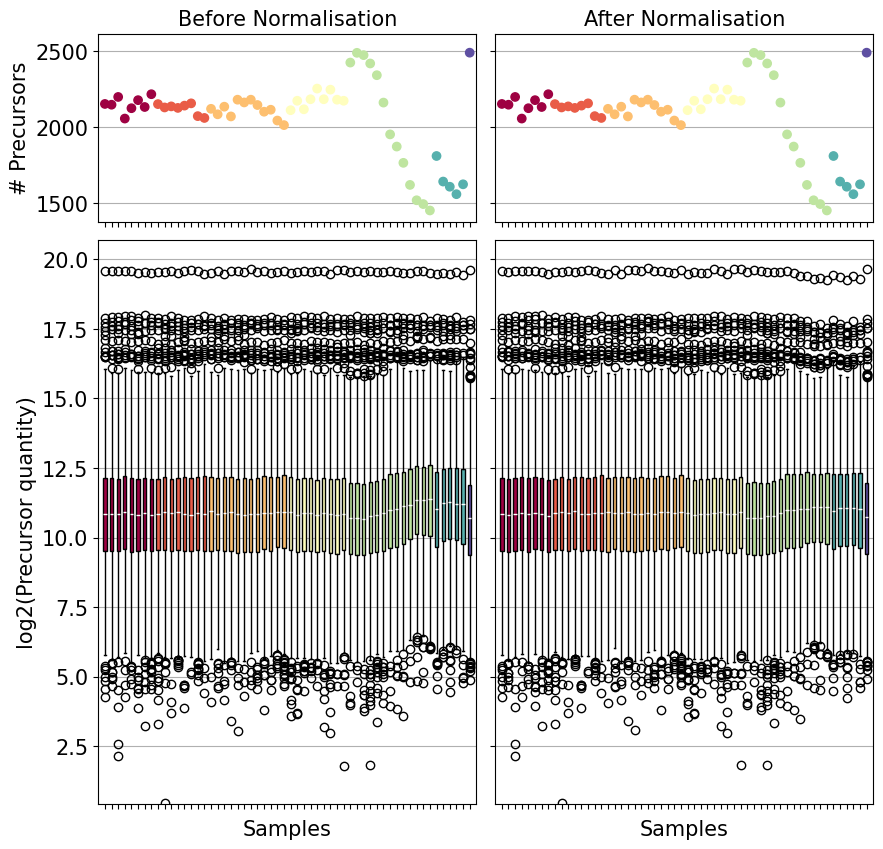

In [9]:
qa.plot_qa_box_int_and_number(data_origin, 
                              metadata_df, 
                              data_processed, 
                              sample_type = None, 
                              sample_type_column = None,
                              size = (10,10), 
                              step = "Normalisation", 
                              outfile = "F01.png", 
                              use_metadata_coloring = True, 
                              column_color = "MS.Batch",
                              )

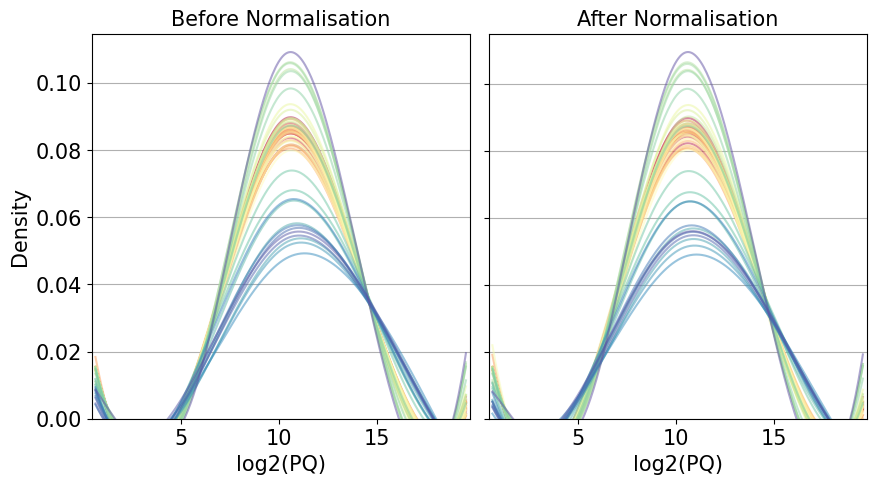

In [10]:
qa.plot_distribution(data_origin, 
                     metadata_df, 
                     data_processed, 
                     outfile = "F05.png",
                     step = "Normalisation"
                     )

As the test data had only static filtering applied beforehand i.e. many very sparse precursors are still present, a big variance difference in the samples is observed. Thus although the medians are aligned better after normalisation, the variances are deviating strongly between the samples. This means that either another method that also accounts for the variance needs to be used or this property needs to be taken into account in downstream preprocessing steps.